# Enhancer code part 1: reading the regulatory code of brain cell types

## Overview

Every cell in your body carries the same genome, yet a microglium and a neuron use completely different genes. A large part of this difference is decided by **enhancers**: short stretches of non-coding DNA that switch genes on in the right cell type. Enhancers work because **transcription factors (TFs)** bind to them. Each TF recognises a short DNA "word" of roughly 6–15 bp, its **motif**. Which words an enhancer contains, how many, and in which combination is what we call the **regulatory code** or **enhancer code**.

In this practical we read that code out of the enhancers of the mouse cortex, and ask how it relates to **cell type identity**.

The starting point is a deep learning model that has already learned the code. DeepBICCN2 reads 2,114 bp of DNA and predicts how accessible that piece is in each of 19 cortex cell types, having learned this from sequence alone. Asked *which nucleotides* it used for a prediction, it produces a **contribution score** per position. Training that model and producing these scores is covered in the CREsted part of the course; here we take the scores as our raw material and ask what they say about the code.

That is the job of **TF-MINDI**. It cuts the important stretches out of the contribution scores (**seqlets**), works out which known motif each one resembles, groups them, and then lets us ask systematic questions: which motifs does each cell type use, how heavily, which transcription factor is likely to bind them, and do whole enhancers group by the motifs they contain?

In part 2 we turn the question around: if the model knows the code, can we use it to **write** new, synthetic enhancers?

**The workflow of this notebook:**
1. **From contribution scores to seqlets.** Load precomputed contribution scores for 5,700 enhancers, 300 from each of the 19 cell types, and cut out the pieces that matter.
2. **What is each seqlet?** Compare every seqlet with a collection of known motifs, assign a TF family, and cluster them into motifs.
3. **The enhancer code.** Build the cell-type-by-motif code table, and name candidate transcription factors by correlating motif use with gene expression from the same tissue.
4. **From motifs back to identity.** Describe every enhancer by the motifs it contains and ask whether that alone recovers the cell types.

## Biological question

The cortex contains many cell types with very different jobs, and the atlas splits them into 19. They fall into three groups, and we keep that grouping in every figure:

- **non-neuronal cells**: **astrocytes** (`Astro`), which support neurons metabolically; **oligodendrocytes** (`Oligo`) and their precursors (`OPC`), which make myelin; **microglia** (`Micro_PVM`), the immune cells of the brain, which are not even of neural origin; and the vascular cells `Endo` and `VLMC`.
- **excitatory neurons**, which send signals onward and are named after the cortical layer they sit in: `L2_3IT`, `L5IT`, `L6IT`, `L5ET`, `L5_6NP`, `L6CT`, `L6b`.
- **inhibitory interneurons**, which regulate the excitatory ones and are named after the marker they express: `Pvalb`, `Sst`, `SstChodl`, `Vip`, `Lamp5`, `Sncg`.

All 19 carry the same DNA. Their identity is maintained by different sets of active enhancers, and the three groups above are a good yardstick for the results: if the enhancer code really encodes identity, cell types within a group should look more alike than cell types from different groups.

**Research questions**

1. Which short DNA words does the model rely on, and do they correspond to known transcription factor motifs?
2. Which motifs are characteristic of each cell type, which are shared, and how strongly is each one used?
3. Which transcription factor is likely to bind each motif, and is that factor expressed in the right cell type?
4. Is an enhancer's cell type determined by *which* motifs it contains, or is there more to the code?

**How to use this notebook.** Run the cells from top to bottom. Each step starts with an explanation of *why* we do it, followed by the code and an interpretation of the result. Questions in **bold** are meant to make you think; try to answer them before reading on.

## Data

Everything comes from a single-cell **multiome** atlas of the mouse primary motor cortex (Zemke et al., Nature 2023), in which the same nuclei were measured for chromatin accessibility and for gene expression. We use three things from it: contribution scores computed on its enhancers with the DeepBICCN2 model of CREsted (Kempynck & De Winter et al., Nature Methods 2026), the matching RNA-seq, and a published list of mouse transcription factors. All three are distributed together with the TF-MINDI tutorial.

## Part 1: From contribution scores to seqlets

### Selecting the kernel and installing the Python environment

This practical uses its own **Conda/Mamba environment**, `regulatory_genomics_enhancers`. It is separate from the `regulatory_genomics` environment of the single-nucleus and spatial practicals because the deep learning libraries (TensorFlow, CREsted, TF-MINDI) need their own, specific package versions. You only need to create it **once**, and the same environment is used for part 1 and part 2.

Run the following in a **terminal on the computer/VSC cluster where you use Jupyter**, not in a notebook code cell:

```bash
mamba create -n regulatory_genomics_enhancers -c conda-forge python=3.12 pip ipykernel ipywidgets numpy pandas matplotlib seaborn "scanpy>=1.12.5" anndata
conda activate regulatory_genomics_enhancers
pip install tensorflow "crested[motif]" "tfmindi>=2"
```

- **TensorFlow** is the deep learning library that runs the neural network.
- **CREsted** loads trained enhancer models, makes predictions, explains them and designs new sequences.
- **TF-MINDI** groups the important pieces of DNA found by the model into transcription factor motifs, and annotates each motif with the transcription factor family that binds it. Version 2 or newer is required.

The `scanpy>=1.12.5` is not optional: older versions crash when clustering more than a few thousand seqlets with recent SciPy.

The installation may take 10–15 minutes. Then **register a Jupyter kernel**:

```bash
conda activate regulatory_genomics_enhancers
python -m ipykernel install --user --name regulatory_genomics_enhancers --display-name "Python (regulatory_genomics_enhancers)"
jupyter kernelspec list
```

Open the notebook in VS Code or Jupyter and choose **Python (regulatory_genomics_enhancers)** via **Select Kernel** (VS Code) or **Kernel → Change Kernel** (Jupyter).

Everything in this practical runs on a normal laptop CPU; a GPU is not needed (though it will speed things up). The slowest steps take 10–20 minutes and are marked in the text.

### Step 0: Set up the working directory

All data are stored in `data/` and all results in `results/`, next to this notebook. Downloaded motif databases also go into `data/`, so everything belonging to this practical stays in one place.

In [1]:
import os
os.environ["TFMINDI_DATA_DIR"] = "data/tfmindi"  # store downloaded motif databases in data/

import tarfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import tfmindi as tm

DATA = Path("data")
BICCN = DATA / "biccn"
RESULTS = Path("results")
for folder in (DATA, BICCN, RESULTS):
    folder.mkdir(exist_ok=True)

print("TF-MINDI:", tm.__version__)

TF-MINDI: 2.0.0


### A colour convention for the whole practical

Before we plot anything, we fix **one colour per cell type** and use it in every figure of both notebooks. This is worth doing deliberately rather than letting each plotting function pick its own defaults: once you have learned that orange-red means microglia and blue means oligodendrocytes, every later figure becomes readable at a glance.

We also fix the **order** here — non-neuronal, excitatory neurons, inhibitory interneurons — and reuse it in every table and heatmap, so that related cell types always sit next to each other.

In [2]:
# One colour per cell type, used in every figure of both notebooks.
# The order is the one we use everywhere: non-neuronal, then excitatory, then inhibitory.
CELL_TYPE_COLOURS = {
    # non-neuronal
    "Astro":     "#009E73",
    "Oligo":     "#0072B2",
    "OPC":       "#543005",
    "Micro_PVM": "#D55E00",
    "Endo":      "#332288",
    "VLMC":      "#66A61E",
    # excitatory neurons
    "L2_3IT":    "#CC79A7",
    "L5IT":      "#003C30",
    "L6IT":      "#DDCC77",
    "L5ET":      "#B2182B",
    "L5_6NP":    "#E7298A",
    "L6CT":      "#C49C94",
    "L6b":       "#EE8866",
    # inhibitory interneurons
    "Pvalb":     "#E69F00",
    "Sst":       "#882255",
    "SstChodl":  "#A6761D",
    "Vip":       "#56B4E9",
    "Lamp5":     "#BBCC33",
    "Sncg":      "#8C564B",
}
GREY = "#CCCCCC"  # anything without a colour of its own

CELL_TYPES = list(CELL_TYPE_COLOURS)          # all 19, in the order above
CELL_TYPE_GROUPS = {"non-neuronal": CELL_TYPES[:6],
                    "excitatory": CELL_TYPES[6:13],
                    "inhibitory": CELL_TYPES[13:]}

def cell_colour(cell_type):
    """The agreed colour of a cell type."""
    return CELL_TYPE_COLOURS.get(cell_type, GREY)

### Step 1: Where the data comes from

Everything in this notebook starts from **contribution scores**, so it is worth being clear about what they are before we touch them.

A deep learning model, **DeepBICCN2**, was trained on the ATAC-seq atlas to read 2,114 bp of DNA and predict how accessible that piece is in each of 19 cell types. It saw only sequence: no gene names, no positions, no list of transcription factors. Having learned to predict accessibility, it can be asked a second question about any sequence: *which nucleotides did you use to make that prediction?* The answer, one number per position, is a contribution score. Positions the model ignores score near zero; the handful of positions that carry the prediction stand out, and those are the candidate binding sites.

Training that model and computing these scores belongs to the CREsted part of the course. We start from a **precomputed set**, made with that model and published with the TF-MINDI tutorial: for each of the 19 cell types, the 2,000 most cell-type-specific regions, with their one-hot encoded sequence and their contribution scores. For this notebook, we take all 19 cell types and only the top 300 regions each, which is 5,700 enhancers — enough for the statistics to be meaningful and still small enough to get to the results faster.

The same archive also contains two files we need later: single-cell RNA-seq of the same tissue, and a table of mouse transcription factors.

**This download is 1.85 GB and happens once.** If your course provides the file, place `tutorial_data.tar.gz` in `data/biccn/` and the next cell will use it.

In [3]:
bundle = BICCN / "tutorial_data.tar.gz"
tutorial_dir = BICCN / "tutorial_data"
contrib_dir = tutorial_dir / "modisco_results_ft_2000"

if not bundle.exists() and not contrib_dir.exists():
    print("Downloading the TF-MINDI tutorial data (1.85 GB), this takes a while...")
    urlretrieve("https://zenodo.org/records/23879856/files/tutorial_data.tar.gz", bundle)

needed = ([f"tutorial_data/modisco_results_ft_2000/{c}_{k}.npz"
           for c in CELL_TYPES for k in ("oh", "contrib")]
          + ["tutorial_data/mouse_cortex_scrna.h5ad", "tutorial_data/Mus_musculus_TF.txt"])
missing = [n for n in needed if not (BICCN / n).exists()]
if missing:
    with tarfile.open(bundle) as tar:
        tar.extractall(BICCN, members=[tar.getmember(n) for n in missing])
print(f"contribution scores for {len(CELL_TYPES)} cell types, "
      f"plus RNA-seq and the TF table")

contribution scores for 19 cell types, plus RNA-seq and the TF table


In [4]:
N_PER_CELL_TYPE = 300

one_hot_list, contrib_list, labels = [], [], []
for cell_type in CELL_TYPES:
    o = np.load(contrib_dir / f"{cell_type}_oh.npz")["arr_0"][:N_PER_CELL_TYPE]
    c = np.load(contrib_dir / f"{cell_type}_contrib.npz")["arr_0"][:N_PER_CELL_TYPE].astype(np.float32)
    one_hot_list.append(o)
    contrib_list.append(c)
    labels += [cell_type] * len(o)

one_hot_all = np.concatenate(one_hot_list)
contrib_all = np.concatenate(contrib_list)
labels = np.array(labels)
WIDTH = contrib_all.shape[-1]          # 2,114 bp, the model's input length
print(contrib_all.shape, "-> (regions, 4 nucleotides, sequence length)")
print(pd.Series(labels).value_counts().to_string())

(5700, 4, 2114) -> (regions, 4 nucleotides, sequence length)
Astro        300
Oligo        300
OPC          300
Micro_PVM    300
Endo         300
VLMC         300
L2_3IT       300
L5IT         300
L6IT         300
L5ET         300
L5_6NP       300
L6CT         300
L6b          300
Pvalb        300
Sst          300
SstChodl     300
Vip          300
Lamp5        300
Sncg         300


These arrays are already in the shape TF-MINDI expects: regions × 4 nucleotides × sequence length.

## Part 2: What does each important piece of DNA look like?

### Step 2: Cut out the important pieces: seqlets

A **seqlet** is a short stretch of sequence (roughly 10–25 bp) with unusually high contribution scores: a "hotspot" in the contribution track. Each seqlet is a candidate TF binding site that the model actually uses.

`tm.pp.extract_seqlets` calls these "hotspots". The default caller looks at the **absolute** importance, so it finds stretches that push the prediction up as well as stretches that push it down; a TF that *represses* accessibility in a cell type is therefore not missed. There are also other methods available within the framework, feel free to explore them.

In [5]:
seqlets_df, seqlet_matrices = tm.pp.extract_seqlets(
    contrib_all, one_hot_all,
    method="recursive_q99_abs_smooth",   # the default caller: positive and negative seqlets
    threshold=0.01,
)
print(f"{len(seqlet_matrices):,} seqlets in {len(contrib_all):,} regions "
      f"({len(seqlet_matrices) / len(contrib_all):.1f} per region)")
seqlets_df.head()

Processing seqlets:   0%|          | 0/51101 [00:00<?, ?it/s]

51,101 seqlets in 5,700 regions (9.0 per region)


,example_idx,start,end,attribution,score
0,0,1023,1039,8.927565,2.504825
1,0,1052,1068,8.666976,2.152355
2,0,1068,1085,8.223417,2.050911
3,0,1113,1131,10.960779,2.387072
4,0,1130,1146,8.358410,2.354232


Each row is one seqlet: `example_idx` is the region it came from, `start` and `end` its position inside that region, and `attribution` its total contribution. About nine important stretches per enhancer, which fits the idea that an enhancer is a cluster of several TF binding sites.

### Step 3: A motif collection to compare the seqlets with

To find out which TF could bind each seqlet, we compare it with a large collection of known TF motifs. A motif is stored as a **position weight matrix**: for every position, the probability of A, C, G and T.

TF-MINDI uses the Aerts lab **v11 motif collection**: about 55,000 motifs gathered from many databases (JASPAR, HOCOMOCO, Cis-BP, ...). Two things make our analysis possible:

1. The motifs were **grouped into clusters** of similar motifs.
2. Every cluster was **annotated with the transcription factor family** that binds it, and we can link further with specific TF candidates using AnimalTFDB4.

So instead of us recognising motifs by eye, the collection tells us which TF family a seqlet resembles.

`tm.fetch_motif_collection` downloads the collection (64 MB) into `data/tfmindi/` the first time and reuses it afterwards. Comparing every seqlet with all 55,000 motifs would be slow and largely redundant, since the clusters contain near-duplicates, so we take a sample of 20 motifs per cluster — still covering every cluster.

In [6]:
N_MOTIFS_PER_CLUSTER = 20

archive = tm.fetch_motif_collection("v11")
motif_collection = tm.MotifCollectionData(archive)
motifs = motif_collection.get_motifs(N_MOTIFS_PER_CLUSTER)
print(f"{len(motif_collection.metadata):,} motifs in the collection, "
      f"{len(motifs):,} sampled for the comparison")

55,260 motifs in the collection, 4,770 sampled for the comparison


In [7]:
motif_collection.metadata["tf_family"].value_counts().head(10)

tf_family
zf-C2H2      5997
Homeobox     3308
bHLH         1369
TF_bZIP      1286
Fork_head     626
ETS           615
HMG           571
ZBTB          545
Pou           373
RXR-like      321
Name: count, dtype: int64

The families differ enormously in size: zinc fingers (`zf-C2H2`) are by far the largest group, with thousands of motifs, while a family such as `IRF` has only a few hundred. Keep this in mind for when we read the annotations later.

### Step 4: Compare every seqlet with every motif

`tm.pp.calculate_motif_similarity` compares each seqlet with each motif using **TomTom**, a classic tool that slides two matrices along each other and scores how well they match. The result is a table with one row per seqlet and one column per known motif.

This is a useful representation: every seqlet is now described by **how similar it is to each known motif**, just as every cell in single-cell RNA-seq is described by how much it expresses each gene.

We also pass `reference=`, which additionally projects every seqlet into the collection's own motif space. That projection is what the next step uses to name the TF family.

In [8]:
similarity, projection = tm.pp.calculate_motif_similarity(
    seqlet_matrices, motifs,
    chunk_size=50000,   # limits memory use, does not change the result
    n_nearest=100,      # store only the 100 best matches per seqlet
    reference=motif_collection,
    n_motifs_per_reference_cluster=N_MOTIFS_PER_CLUSTER,
)
print("similarity:", similarity.shape, " projection:", projection.shape)

Processing chunks:   0%|          | 0/2 [00:00<?, ?it/s]

similarity: (51101, 4770)  projection: (51101, 50)


TF-MINDI stores everything in an AnnData object, the same data structure you used with Scanpy: seqlets are the observations (`.obs`), known motifs the variables (`.var`), and the similarity table is `.X`. We also record which cell type each seqlet came from.

In [9]:
adata = tm.pp.create_seqlet_adata(
    similarity, seqlets_df,
    oh_sequences=one_hot_all,
    contrib_scores=contrib_all,
    motif_collection=motifs,
)
adata.obsm[f"X_ref_proj_{N_MOTIFS_PER_CLUSTER}"] = projection
adata.obs["cell_type"] = pd.Categorical(labels[adata.obs["example_idx"].astype(int)],
                                        categories=CELL_TYPES)
adata

AnnData object with n_obs × n_vars = 51101 × 4770
    obs: 'example_idx', 'start', 'end', 'attribution', 'score', 'example_oh_idx', 'example_contrib_idx', 'cell_type'
    var: 'motif_ppm'
    uns: 'unique_examples'
    obsm: 'X_ref_proj_20'
    layers: None (.X)

### Step 5: Which TF family does each seqlet look like?

`tm.tl.predict_tf_family_seqlets` takes each seqlet, looks up its nearest known motifs in the projected space, and lets them vote on which **cluster** of the collection the seqlet belongs to. Each cluster carries a TF family annotation, so the seqlet inherits a family name.

In [10]:
CLUSTER_RESOLUTION = 5.0

tm.tl.predict_tf_family_seqlets(
    adata=adata,
    motif_collection=motif_collection,
    cluster_resolution=CLUSTER_RESOLUTION,
    n_motifs_per_reference_cluster=N_MOTIFS_PER_CLUSTER,
)
family_column = f"predicted_{CLUSTER_RESOLUTION}_predicted_family"
adata.obs["tf_family"] = [name.split("|")[1] if "|" in name else name
                          for name in adata.obs[family_column]]
adata.obs["tf_family"].value_counts().head(12)

Reusing existing reference projection in obsm['X_ref_proj_20'] ...
building index ...


predicting ...


Added following keys to adata.obs: 
	predicted_5.0_predicted_cluster
	predicted_5.0_predicted_cluster_score
	predicted_5.0_predicted_family


tf_family
zf-C2H2      12034
Homeobox      8594
bHLH          5196
CTF_NFI       4871
HMG           3108
Fork_head     2647
TF_bZIP       1814
THR-like      1689
SRF           1542
ARID          1509
Pou           1387
T-box         1037
Name: count, dtype: int64

Now that we know which families are present, we fix **one colour per TF family** as well, the same way we fixed one colour per cell type. TF-MINDI keeps these colours on the object itself (`adata.uns`), so every plot it draws from here on — the t-SNEs, the annotated enhancers of Step 9 — uses the same colour for the same family.

In [11]:
# one fixed colour per TF family, stored on the object so every TF-MINDI plot reuses it
families = sorted(adata.obs["tf_family"].dropna().unique())
# tab20 positions 14 and 15 are greys, which we keep for "not followed", so skip them
wheel = [plt.get_cmap("tab20")(i / 20) for i in range(20) if i not in (14, 15)] +         [plt.get_cmap("tab20b")(i / 20) for i in range(20)]
FAMILY_COLOURS = {family: mcolors.to_hex(wheel[i % len(wheel)])
                  for i, family in enumerate(families)}
adata.uns["tf_family_colors"] = FAMILY_COLOURS
adata.uns["cell_type_colors"] = {c: cell_colour(c) for c in adata.obs["cell_type"].unique()}
print(f"{len(FAMILY_COLOURS)} TF families, each with its own colour")

54 TF families, each with its own colour


Several families you would hope to see in brain cells are already here: `HMG` (the family of SOX factors), `CTF_NFI` (the NFI factors), `bHLH`, `IRF` and `ETS`. The very large `zf-C2H2` count is partly real and partly an artefact of that family being the largest in the collection, so an uncertain seqlet lands there easily.

**Question**: Each seqlet is annotated by a vote among its nearest known motifs. Why does a family with thousands of motifs in the collection win such a vote more easily than a family with a few hundred?

### Step 6: Group the seqlets into motifs

Many seqlets are instances of the same motif: all SOX binding sites look alike. We find these groups exactly the way you clustered nuclei in the single-nucleus RNA-seq practical:

| single-nucleus RNA-seq | TF-MINDI |
|---|---|
| a nucleus | a seqlet |
| expression of a gene | similarity to a known motif |
| PCA → neighbour graph → Leiden | PCA → neighbour graph → Leiden |
| UMAP / t-SNE to visualise | t-SNE to visualise |
| marker genes → cell type | matching motifs → TF family |

This takes a few minutes for 51,000 seqlets.

In [12]:
tm.tl.embed_and_cluster(adata, resolution=1.0)

Using CPU backend for clustering operations...
Computing PCA...


Computing neighborhood graph...


Computing t-SNE embedding...


Performing Leiden clustering with resolution 1.0...


Clustering complete. Found 34 clusters.


The t-SNE below shows the result. Each dot is a seqlet, and seqlets resembling the same motifs sit close together. We colour it three ways, because each answers a different question.

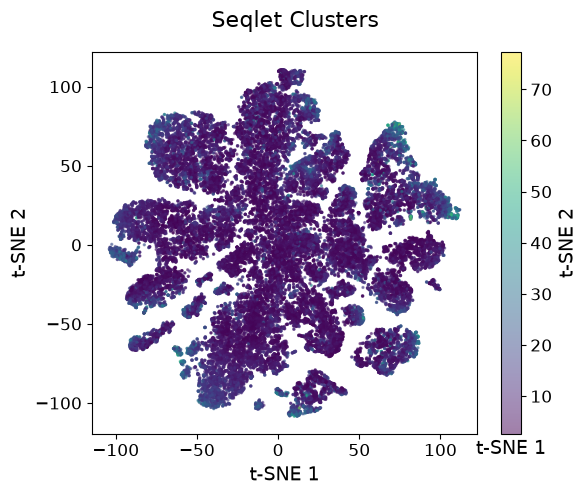

In [13]:
# 1. how strong is each seqlet?
tm.pl.tsne(adata, color_by="attribution", s=2, alpha=0.5, width=6, height=5)

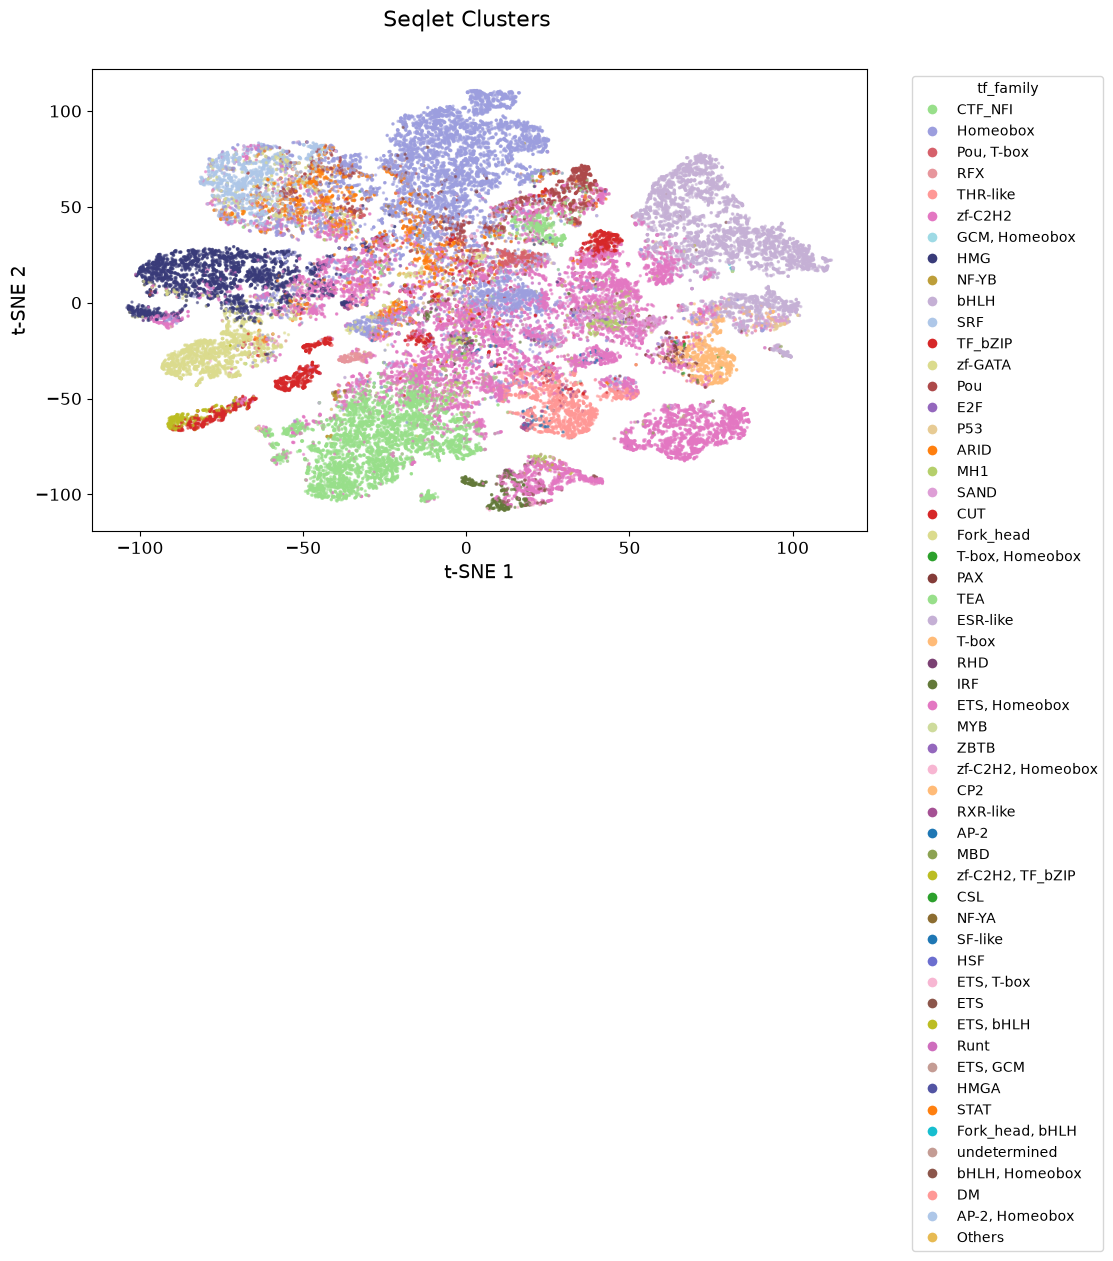

In [14]:
# 2. which TF family does it resemble?
tm.pl.tsne(adata, color_by="tf_family", s=2, alpha=0.5, width=10, height=6)

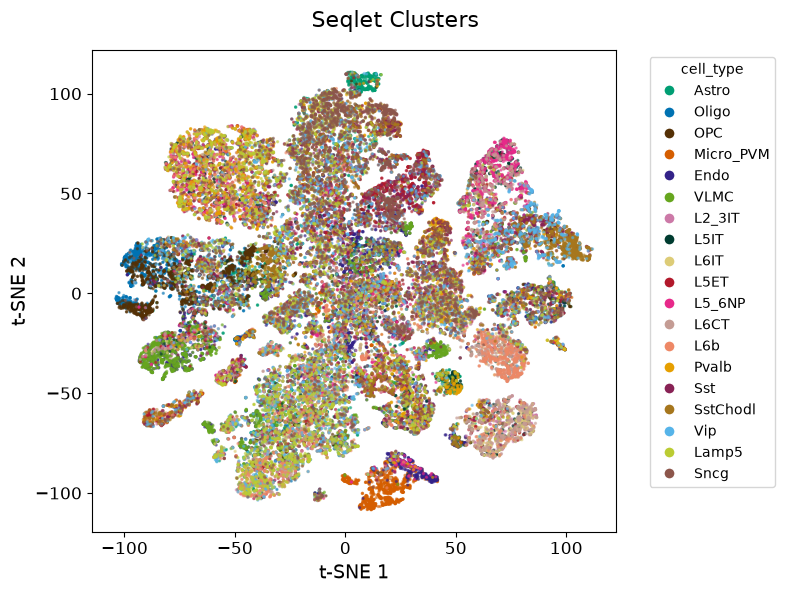

In [15]:
# 3. which cell type did the enhancer it came from belong to?
tm.pl.tsne(adata, color_by="cell_type", s=2, alpha=0.5, width=8, height=6)

Read together, these three views already tell the story of this notebook:

- **by contribution**: weak seqlets sit in loose groups, strong ones form tight clusters. Tight clusters are the trustworthy ones.
- **by TF family**: the clusters correspond to families, which is the sanity check that the grouping picks up motif identity rather than noise.
- **by cell type**: and here is the interesting part. Several clusters are dominated by a *single colour*. Those are motifs used by one cell type and not the others, which is exactly what a cell-type-specific code would look like.

**Question**: In single-cell RNA-seq, a cluster is not automatically a cell type. In the same way, why is a seqlet cluster not automatically a TF motif?

### Step 7: A consensus motif for every cluster

To see what each cluster looks like, TF-MINDI aligns all its seqlets and summarises them as one **consensus motif**, drawn as a sequence logo. In a logo the height of a letter shows how conserved that position is: tall letters are always the same, short letters vary.

In [16]:
patterns = tm.tl.create_patterns(adata, annotation_col="tf_family", max_n=500)

Creating patterns for 34 clusters...


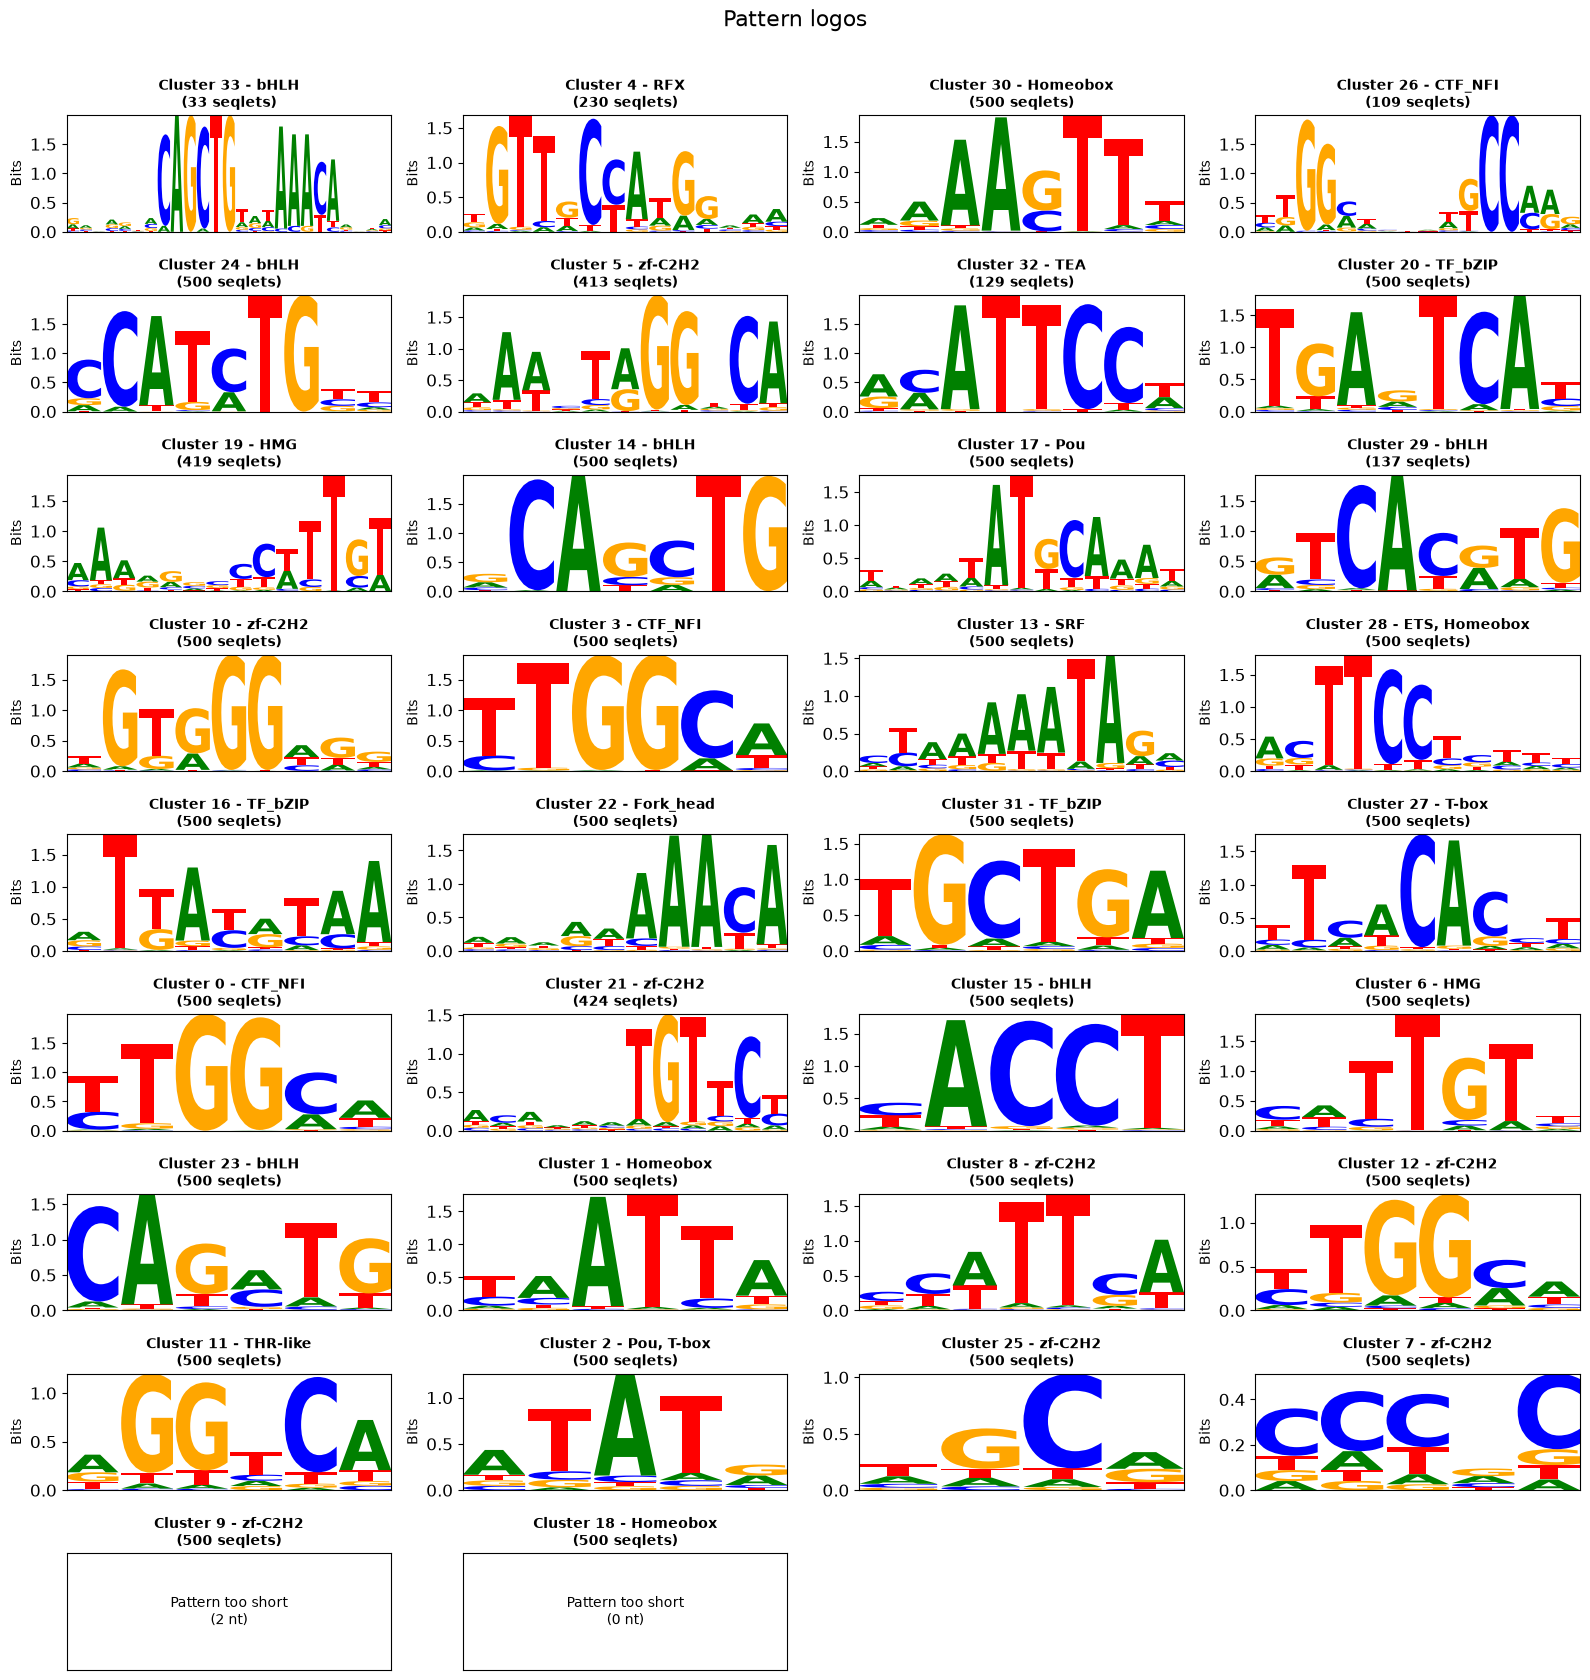

In [17]:
tm.pl.pattern_logos(patterns, sort_by="ic", ncols=4, ic_threshold=0.2, min_nucleotides=4)

Now each cluster has a face, and the title gives the TF family voted for it. Clusters whose seqlets do not agree on a motif give a logo too short to draw; those are groups of weak or heterogeneous seqlets rather than real binding sites, which is an honest outcome, rather than a bug, for clusters whose seqlets are maybe more noisy.

Keep in mind that the family label is a hint, not a conclusion: it comes from a vote among similar motifs, and large families win votes easily. **Read the logo, and treat the family name as a suggestion/likely candidate.**

The grid above shows the motifs but loses the map: it does not say which cluster sits next to which. The next plot puts each logo **on the t-SNE itself**, at the position of the cluster it summarises.

Read it as a landscape. Neighbouring logos look alike, because the t-SNE placed seqlets by motif similarity in the first place: you can see families spread over several nearby clusters, with variants of one motif shading into each other. Clusters far apart are genuinely different words.

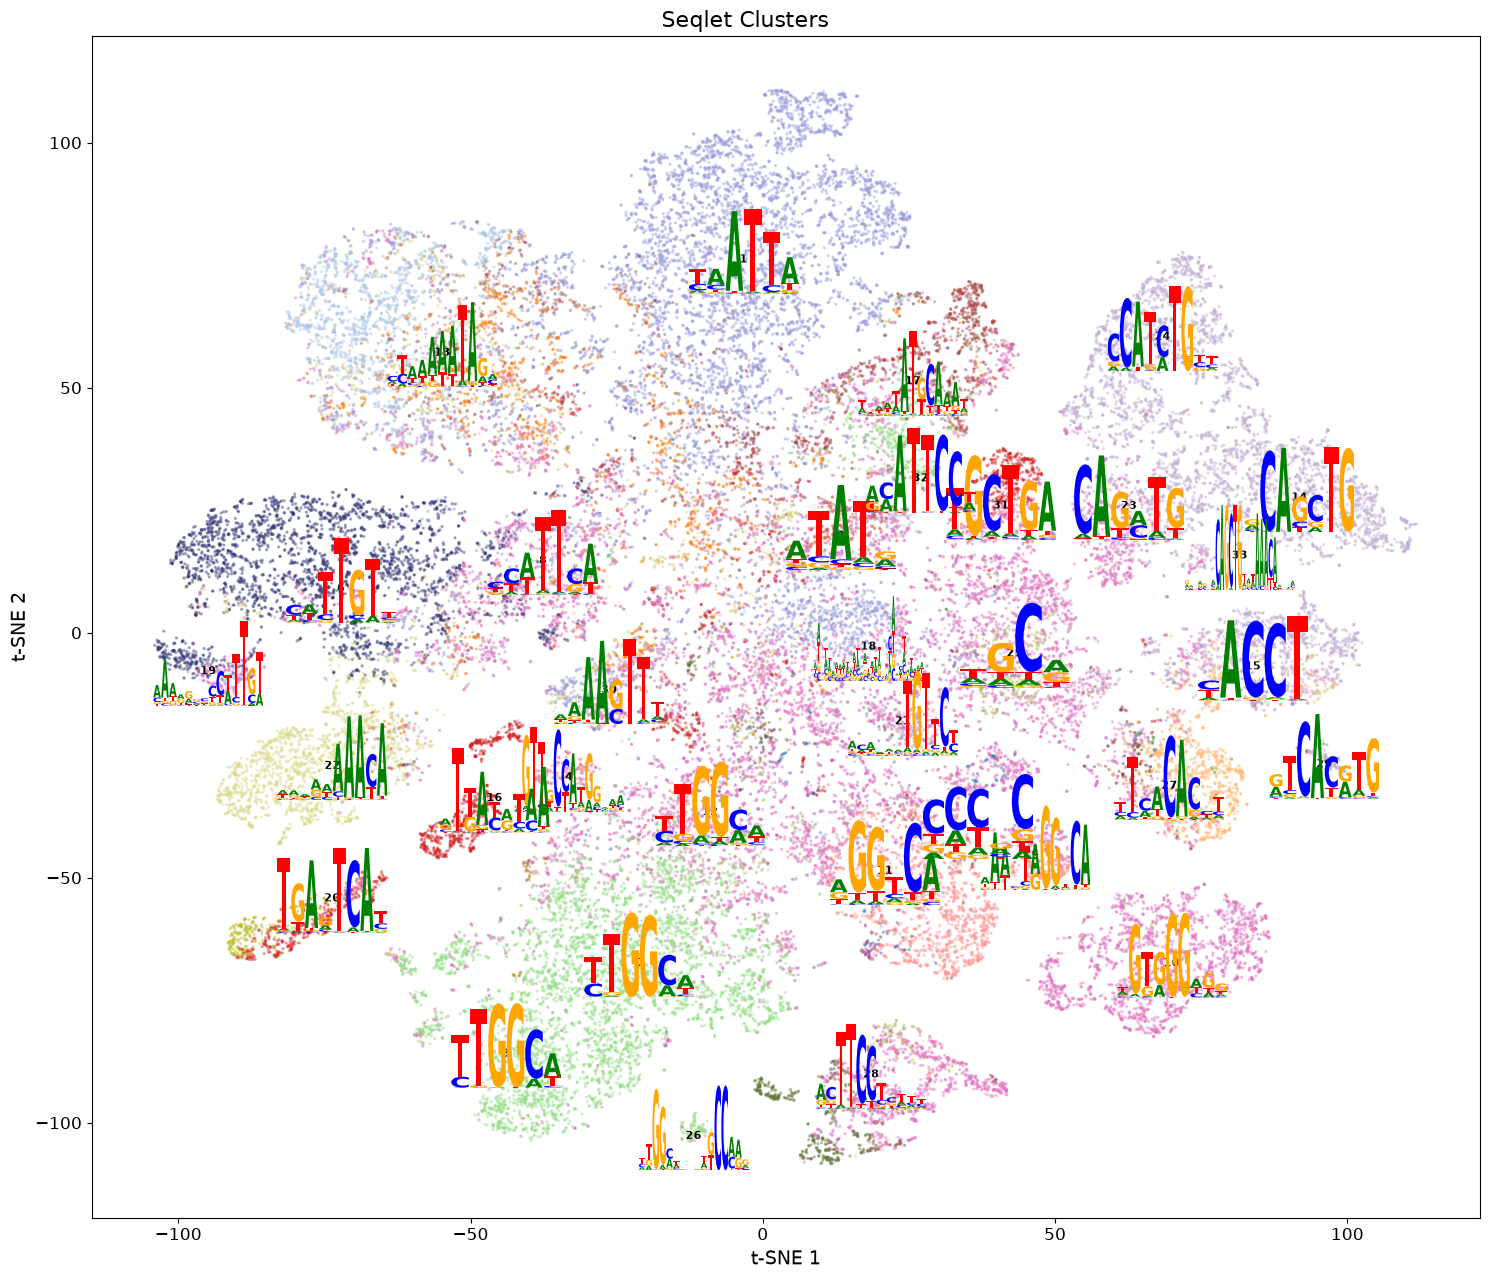

In [18]:
tm.pl.tsne_logos(adata, patterns=patterns, color_by="tf_family", patterns_by="leiden",
                 logo_width=1.1, logo_height=0.85, s=2, alpha=0.35,
                 ic_threshold=0.2, min_nucleotides=4, min_seqlets=10,
                 gray_background=False,   # colour the seqlets by family, as in the t-SNE above
                 show_legend=False, width=15, height=13)   # same colours as the t-SNE above

## Part 3: The enhancer code of each cell type

### Step 8: The code table

This is the question we set out to answer, and TF-MINDI has a dedicated view for it: the **code table**. Every seqlet knows two things — which cluster of similar motifs it belongs to, and which cell type's enhancer it was cut out of. Crossing those two gives the table.

We deliberately do **not** use the broad TF family here. "bHLH" covers dozens of different variations of this family's motifs that may be used in a cell type-dependant manner; the Leiden clusters of Step 6 are the refined version, each one a single motif. To keep them readable we label every cluster with its number, its consensus sequence and the family it was voted into.

The dot plot shows two numbers at once:

- **dot size** is how many seqlets of that cluster an average enhancer of that cell type contains — *how often* the word is used;
- **dot colour** is the mean contribution of those seqlets — *how much the model leans on it* when it is there.

A motif can be frequent but weak (a common word that adds little, or whose contributions are "diluted" due to the abundance), or rare but strong (used in few enhancers, decisive where it appears).

In [19]:
def consensus(pattern, min_information=0.2):
    """The consensus sequence of the informative core of a pattern, and how informative it is."""
    if pattern is None:
        return "", 0.0
    ppm = np.asarray(pattern.ppm)
    if ppm.shape[0] == 4:
        ppm = ppm.T
    start, end = pattern.ic_trim(min_information)
    if end <= start:
        return "", 0.0
    core = ppm[start:end]
    return ("".join("ACGT"[i] for i in core.argmax(axis=1)),
            float(np.mean(np.asarray(pattern.ic())[start:end])))

# a readable name for every seqlet cluster: number, consensus motif, voted family
cluster_family = adata.obs.groupby("leiden", observed=True)["tf_family"].agg(
    lambda v: v.mode().iloc[0])
cluster_label = {c: f"{c}  {consensus(patterns.get(c))[0] or '(no clear motif)'}  ·  {cluster_family[c]}"
                 for c in adata.obs["leiden"].cat.categories}
adata.obs["motif_cluster"] = [cluster_label[c] for c in adata.obs["leiden"]]
print(f"{len(cluster_label)} motif clusters")

34 motif clusters


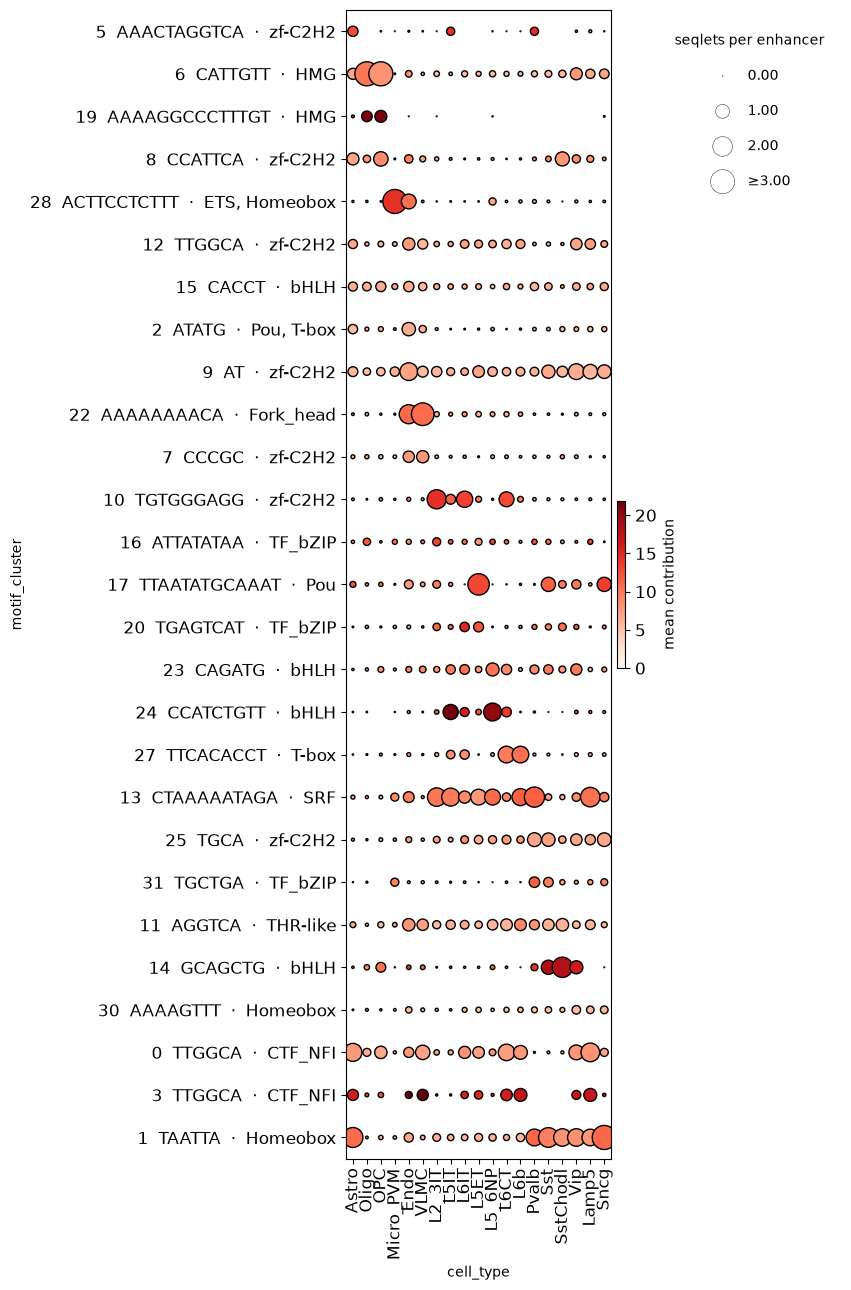

In [20]:
tm.pl.code_table_dotplot(
    adata,
    seqlet_annotation_key="motif_cluster",
    cell_type_key="cell_type",
    size_by="example_idx",        # dot size: average number of seqlets per enhancer
    color_by="attribution",       # dot colour: how strongly the model uses them
    cell_type_order=CELL_TYPES,
    order_diagonal_by="size",
    min_size_value=0.25, max_dotsize=3,
    size_legend_title="seqlets per enhancer",
    colorbar_label="mean contribution",
    width=9, height=13,
)

Now the rows are **motifs**, and you can read the code straight off the plot. A few examples:

- **Cluster 28, `ACTTCCTCTTT`** — a large, dark dot in `Micro_PVM` and essentially nothing anywhere else. That is the `ETS`/PU.1 site, and it is both frequent *and* heavily used, in one cell type only.
- **Clusters 6 and 19, both `HMG`/SOX.** Cluster 6 reads `CATTGTT` and is large and pale across `Oligo` **and** `OPC`: a word the whole oligodendrocyte lineage uses often, without the model leaning on any single copy. Cluster 19 reads a longer `AAAAGGCCCTTTGT` and is small and almost black in `Oligo`: rarer, and decisive where it appears. The family table would have merged these two into one row called "HMG" and hidden the distinction.
- **Cluster 22, `AAAAAAAACA`** (`Fork_head`) sits in `Endo` and `VLMC` — the two vascular types, as in the embedding.
- **Cluster 1, `TAATTA`** (`Homeobox`) is large across all six inhibitory types at once. Not one cell type's word, but one *lineage's*.
- **Cluster 27, `TTCACACCT`** (`T-box`) belongs to `L6CT` and `L6b`, the deep-layer excitatory neurons.

Now look at clusters **0** and **3**. They have the *same* consensus, `TTGGCA`, and the same family label, `CTF_NFI` — yet they behave somewhat differently. Cluster 0 is a row of big pale dots spread over half the atlas: common and weakly used. Cluster 3 is a row of smaller dark ones more concentrated in `VLMC`, `L6CT`, `L6b` and `Vip`: rare and strongly used.

Two seqlets can share their core six letters and still be different elements. TF-MINDI did not separate them because of the word itself — it had nothing else to go on in the consensus — but because of everything around it: flanking bases, the company the sites keep, and how the model treats them.

**Question**: Find a cluster whose consensus motif looks nothing like its family label. Which of the two would you trust, and what would you check to decide?

### Step 9: Which transcription factor actually binds it? Comparing with TF expression

Everything so far rests on sequence alone, and that leaves a real gap. A motif tells us which *family* binds it, but a family can have twenty members. `HMG` covers the whole SOX family; knowing the motif does not tell us whether this oligodendrocyte enhancer is bound by SOX10, SOX8 or SOX9.

There is independent information we have not used yet. The atlas is a **multiome**: the same nuclei were measured for accessibility *and* for gene expression. So for every candidate TF we can ask whether it is actually transcribed in the cell type whose enhancers carry its motif.

That gives us a sharper criterion than either source alone. We look for motif clusters whose **use across cell types tracks the expression of a specific TF across the same cell types**. If a cluster's seqlets are abundant in microglia and the gene *Spi1* is expressed in microglia and nowhere else, those two patterns correlate, and we have a named candidate rather than a family label.

Keep in mind, this is still a correlation evaluation, not a binding experiment — a hit here is a well-supported candidate, not necessarily a proof that this factor binds this motif in this cell type.

In [21]:
# single-cell RNA-seq of the same nuclei, as raw counts
gex = ad.read_h5ad(tutorial_dir / "mouse_cortex_scrna.h5ad")
# the RNA labels are written differently ("L2/3 IT", "Micro-PVM"), so normalise them
gex.obs["cell_type"] = (gex.obs["subclass_Bakken_2022"].astype(str)
                        .str.replace(" ", "", regex=False)
                        .str.replace("-", "_", regex=False)
                        .str.replace("/", "_", regex=False))
print(gex.shape, "-> (nuclei, genes)")

# the usual normalisation: equal library size per nucleus, then log
gex.layers["counts"] = gex.X.copy()
sc.pp.normalize_total(gex)
sc.pp.log1p(gex)

print("nuclei per cell type we follow:")
print(gex.obs["cell_type"].value_counts()[CELL_TYPES].to_string())

(39470, 24275) -> (nuclei, genes)


nuclei per cell type we follow:
cell_type
Astro        2907
Oligo        5165
OPC           215
Micro_PVM    2880
Endo          359
VLMC          520
L2_3IT       7005
L5IT         9092
L6IT          979
L5ET          346
L5_6NP        730
L6CT         4257
L6b           293
Pvalb        1604
Sst          1137
SstChodl       56
Vip           845
Lamp5         963
Sncg          117


In [22]:
# which transcription factors belong to which family (AnimalTFDB4)
tf_db = pd.read_table(tutorial_dir / "Mus_musculus_TF.txt")
family_to_tf = (tf_db[["Family", "Symbol"]].dropna()
                .groupby("Family")["Symbol"].agg(set).to_dict())
print(f"{len(tf_db):,} mouse transcription factors in {len(family_to_tf)} families")

1,611 mouse transcription factors in 72 families


Before plotting we pick the clusters worth looking at. `tm.tl.get_code_table` gives the same cell-type-by-cluster table as before, now counting seqlets per region; we keep any cluster that appears in at least a quarter of the enhancers of some cell type. We also set the correlation threshold at 0.5 rather than something stricter: this is a screen for candidates, and a hard cut-off would throw away real factors that are expressed in more than one place.

In [23]:
code_table = tm.tl.get_code_table(
    metadata=adata.obs,
    seqlet_annotation_key=f"predicted_{CLUSTER_RESOLUTION}_predicted_cluster",
    cell_type_key="cell_type",
    aggregate_by="example_idx",
    aggregation_func="count",
    normalize_per_aggregate_by=True,
)
clusters_of_interest = [int(str(c).split("|")[0])
                        for c in code_table.index[code_table.max(axis=1) >= 0.25]]
print(f"{len(clusters_of_interest)} motif clusters used at least once in four enhancers")

33 motif clusters used at least once in four enhancers


`tm.tl.correlate_tf_expression` pairs every cluster with **every TF of the family it was annotated with**, so a cluster assigned to `zf-C2H2` comes back paired with over a hundred zinc-finger proteins. Those rows are not wrong, but they carry no information: a family with a hundred interchangeable members cannot tell us which protein binds. We therefore drop clusters that match more than 15 expressed factors, and for the rest we keep the **three best-correlated** ones.

In [24]:
MAX_TFS_PER_CLUSTER = 15   # families any bigger than this cannot name a candidate
N_TFS_SHOWN = 3            # per cluster, the best-correlated ones

correlations = tm.tl.correlate_tf_expression(
    seqlet_adata=adata,
    gene_expression_adata=gex,
    family_to_tf=family_to_tf,
    motif_collection=motif_collection,
    motif_collection_cluster_resolution=str(CLUSTER_RESOLUTION),
    seqlet_annotation_key=f"predicted_{CLUSTER_RESOLUTION}_predicted_cluster",
    cell_type_key="cell_type",
)
pairs = correlations[correlations["motif_collection_cluster"].isin(clusters_of_interest)
                     & (correlations["correlation_coef"] >= 0.5)]

n_tfs = pairs.groupby("motif_collection_cluster").size()
specific = n_tfs[n_tfs <= MAX_TFS_PER_CLUSTER].index
best = (pairs[pairs["motif_collection_cluster"].isin(specific)]
        .sort_values("correlation_coef", ascending=False)
        .groupby("motif_collection_cluster").head(N_TFS_SHOWN))

print(f"{len(n_tfs)} clusters have a correlated factor; "
      f"{len(specific)} of them belong to a family small enough to name one")

annotating clusters:   0%|          | 0/150 [00:00<?, ?it/s]

28 clusters have a correlated factor; 19 of them belong to a family small enough to name one


annotating clusters:   0%|          | 0/150 [00:00<?, ?it/s]

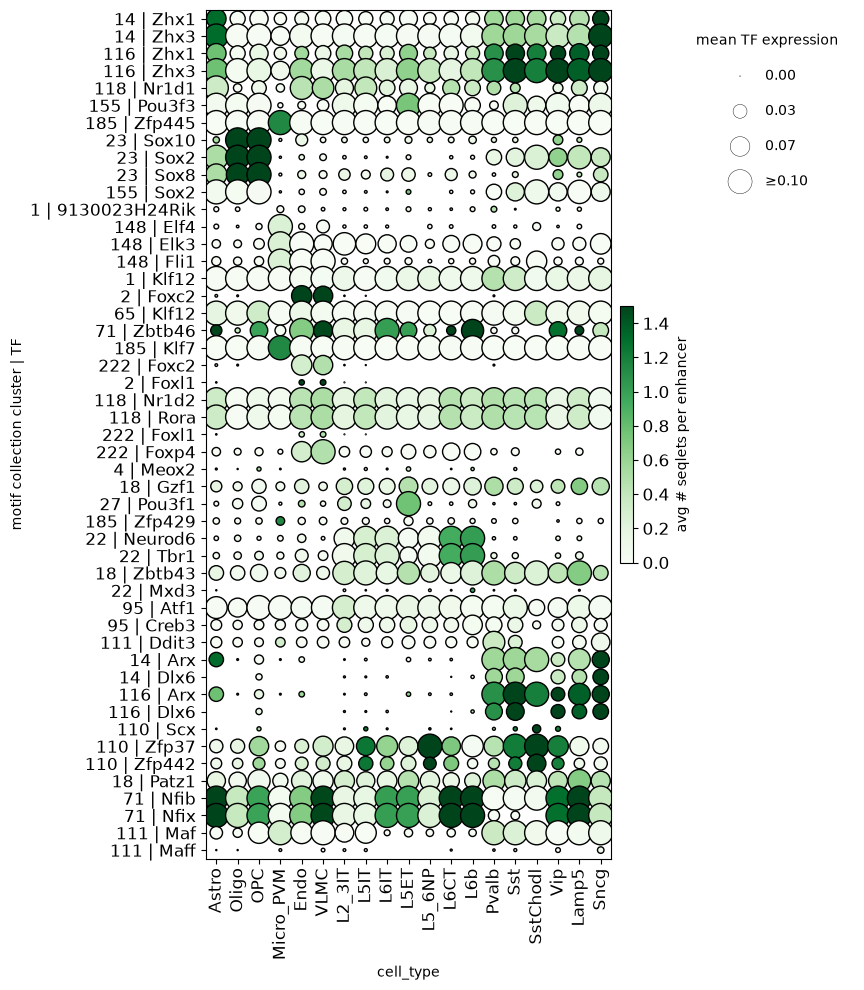

In [25]:
tm.pl.code_table_tf_expression_dotplot(
    seqlet_adata=adata,
    gene_expression_adata=gex,
    family_to_tf=family_to_tf,
    motif_collection=motif_collection,
    motif_collection_cluster_resolution=str(CLUSTER_RESOLUTION),
    seqlet_annotation_key=f"predicted_{CLUSTER_RESOLUTION}_predicted_cluster",
    cell_type_key="cell_type",
    motif_collection_clusters=sorted(specific),
    tfs=sorted(set(best["transcription_factor"])),
    min_correlation_coef=0.5,
    cell_type_order=CELL_TYPES,
    order_diagonal_by="size",
    max_dotsize=0.1,
    colorbar_label="avg # seqlets per enhancer",
    cmap="Greens",
    vmax=1.5,   # the SOX row reaches 4 and would flatten everything else
    width=9, height=10,
)

Each row is a **motif cluster paired with a transcription factor** whose expression tracks that cluster's use across the 19 cell types. The colour is how often the motif appears per enhancer; the dot size is how strongly that factor is expressed. A row where colour and size peak in the same column is a candidate worth believing.

One note on the colour scale: it is capped at 1.5 seqlets per enhancer. The `SOX` row below reaches 4, and on an uncapped scale it would be the only thing visible — every rarer motif would be washed out to white. Capping keeps the rare ones readable, at the cost of saturating the common one.

Look at what comes out:

- **Cluster 23 is paired with `Sox10`** (correlation 0.78), and it is by far the darkest row in the whole figure: around 4 seqlets per enhancer in `Oligo` and 2.5 in `OPC`, and almost nothing anywhere else. *Sox10* expression peaks in exactly those two cell types. SOX10 is the master regulator of the oligodendrocyte lineage. The motif, the enhancers and the RNA all agree.
- **Cluster 22 is paired with `Tbr1`** (0.89) and with `Neurod6` (0.70). Its four strongest columns — `L6b`, `L6CT`, `L5IT`, `L6IT` — are all excitatory, and no inhibitory type comes close. TBR1 and NEUROD6 are classic determinants of excitatory cortical neurons.
- **Cluster 116 is paired with `Dlx6` and `Arx`** and is used almost exclusively by the inhibitory types: `Sncg`, `Vip`, `Sst` and `Lamp5`. The DLX factors are the switch that makes a forebrain neuron GABAergic, so this is the inhibitory counterpart of the row above.
- **Cluster 148 is paired with `Fli1` (0.86), `Elk3` (0.80) and `Elf4` (0.72)**, all `ETS` factors, and its colour sits in `Micro_PVM` and essentially nowhere else. This is the microglial `ETS` word of Step 8, now with candidate factors attached.
- **Cluster 222 is paired with three `Fork_head` factors** — `Foxp4`, `Foxc2`, `Foxl1`, all correlating above 0.8 — and sits in `VLMC` and `Endo`, the blood-vessel cells.
- **Cluster 71 is paired with `Nfib` (0.85) and `Nfix`**, the `CTF_NFI` family, strongest in `Astro` and `Lamp5`. NFIB and NFIX drive astrocyte differentiation.

Now the honest part of this figure. Those three FOX factors are not three findings; they are **one** finding printed three times. Twelve FOX proteins passed the correlation threshold for cluster 222 and we are showing the best three, because every FOX protein binds essentially the same word. Expression narrows the field — these are the ones transcribed in vascular cells — but it cannot pick a winner, and neither can the sequence. The same is true of cluster 23 and its three SOX factors, and of cluster 148 and its eight `ETS` factors.

This is the ceiling of the method, and it is a useful thing to understand about regulatory genomics in general. Sequence tells you the **family**. Expression tells you which **members are present**. Neither tells you which protein is sitting on that piece of DNA. Answering that takes an experiment — a ChIP-seq, a knockout, a footprint — or more advanced computational analyses.

**Question**: Cluster 71 is paired with `Nfib`, but it is coloured in almost every column, not only in `Astro`. Is a motif that every cell type uses evidence against it mattering? What would you need to know to decide?

### Step 10: Annotate an enhancer with its motifs

Finally, we go back to single enhancers and draw their contribution scores with every seqlet coloured by the TF family of its cluster. This turns the "mysterious" contribution track of Step 6 into an annotated enhancer: a sequence built from several TF binding sites.

Micro_PVM: region 1184, zooming to 941-1191


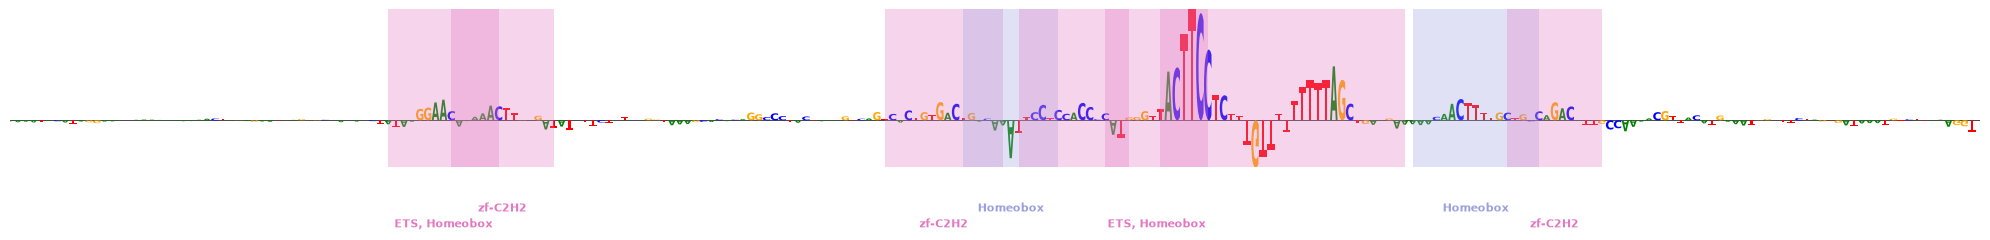

Oligo: region 364, zooming to 1470-1820


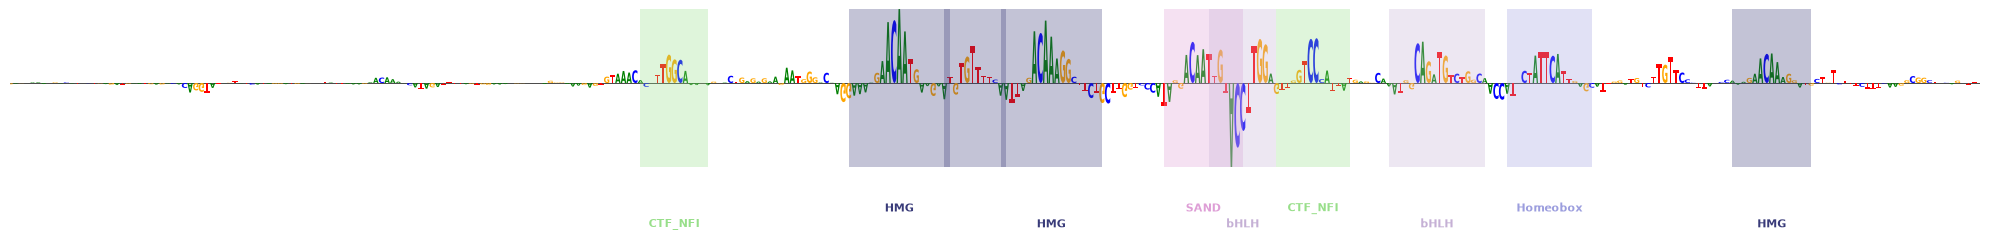

In [26]:
zone_of = adata.obs.groupby("example_idx", observed=True)["cell_type"].first()
strongest = adata.obs.groupby("example_idx", observed=True)["attribution"].sum().sort_values(ascending=False)

def seqlet_span(idx, pad=40, min_span=250, max_span=350):
    """The busiest stretch of a region, so we can zoom onto its motifs."""
    seqlets = adata.obs[adata.obs["example_idx"] == idx]
    start, end = int(seqlets["start"].min()) - pad, int(seqlets["end"].max()) + pad
    if end - start > max_span:
        # seqlets often come in two groups far apart; keep the window holding the most
        weight = np.zeros(WIDTH)
        for s, e, a in zip(seqlets["start"], seqlets["end"], seqlets["attribution"]):
            weight[int(s):int(e)] += a
        densest = int(np.argmax(np.convolve(weight, np.ones(max_span), mode="valid")))
        start, end = densest, densest + max_span
    if end - start < min_span:
        centre = (start + end) // 2
        start, end = centre - min_span // 2, centre + min_span // 2
    return max(0, start), min(WIDTH, end)

for cell_type in ["Micro_PVM", "Oligo"]:
    idx = next(int(i) for i in strongest.index if zone_of[int(i)] == cell_type)
    start, end = seqlet_span(idx)
    print(f"{cell_type}: region {idx}, zooming to {start}-{end}")
    tm.pl.region_contributions(adata, example_idx=idx, annotation_col="tf_family",
                               zoom_start=start, zoom_end=end,
                               height=2.5, width=20)

Each enhancer contains several binding sites from a small number of families, and the families differ between the two cell types. This combination of sites, not one single motif, is what makes an enhancer work in one cell type.

### Step 11: Do whole enhancers group by cell type?

So far every dot has been a *seqlet*. Let us go back up one level and ask about whole **enhancers**: if we describe each enhancer only by the motifs it contains, do the cell types separate?

`tm.tl.embed_regions` does exactly this. For every enhancer it averages the positions of its own seqlets in motif space, weighted by how much each seqlet contributes, and lays the enhancers out with a t-SNE. Two enhancers end up close together when they are built from similar motifs.

This is the same trick as before, one level up: seqlets were described by the motifs they resemble, enhancers are described by the seqlets they contain.

In [27]:
region_adata = tm.tl.embed_regions(adata)
print(region_adata)

 [embed] embedding='pca', secondary='50', weighted, normalised
 [embed] Calculating weights
 [embed] Calculating pca embeddings on obsm.X_pca
 [embed] Calculating TSNE reduction...


AnnData object with n_obs × n_vars = 5700 × 50
    obs: 'example_idx', 'cell_type'
    obsm: 'TSNE'
    layers: None (.X)


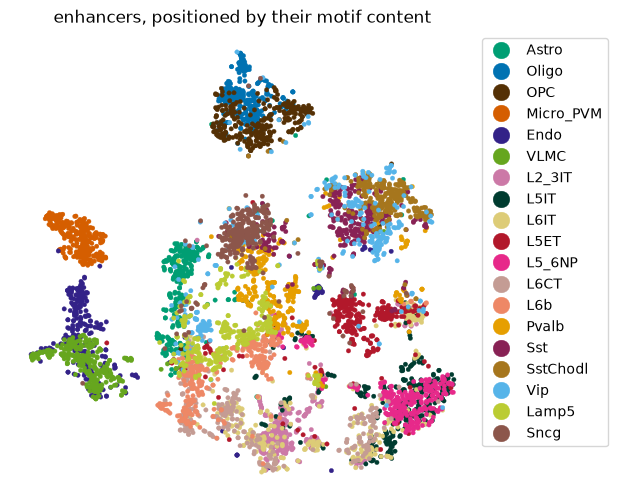

In [28]:
_ = tm.pl.region_tsne(region_adata, color_by="cell_type", plot_legend=True, plot_labels=False,
                      palette=CELL_TYPE_COLOURS,
                      fig_edge=6, dot_size=10, title="enhancers, positioned by their motif content")

Three groups of enhancers break away from the rest entirely:

- `Oligo` **together with** `OPC`, the island at the top;
- `Endo` **together with** `VLMC`, the island at the lower left;
- `Micro_PVM` on its own.

Those pairings are not arbitrary. OPCs are the precursors that become oligodendrocytes; `Endo` and `VLMC` are both cells of the blood vessels. The enhancer code does not separate **cell types** here — it separates **lineages**, and it puts cells of one lineage in the same place because they are more likely to share features in their regulatory code.

Everything else — all thirteen neuronal types plus the astrocytes — forms one large connected mass with internal cluster. Within it, excitatory and inhibitory types occupy different regions.

So the picture is graded, not binary, and the gradient is biological. Microglia, which are not even of neural origin, sit furthest out. The vascular and oligodendrocyte lineages form their own clusters. The neurons, which differ from each other in degree rather than in kind, blur into one another. The further apart two cell types are developmentally, the further apart their enhancers sit.

The overlap inside the mass is informative too, and some of it is our own doing. Averaging a region's motif content throws away **how many** copies of a motif there are, **how good** each match is, and **where** the sites sit relative to each other. The model that produced these contribution scores uses all of that. In part 2 we see one piece of it directly: adding a second and a third copy of the same motif keeps raising the predicted accessibility.

**Question**: Two enhancers sit next to each other in this plot but come from different cell types. Give two explanations that this analysis cannot distinguish between.

### Step 12: How similar are the cell types to each other?

The t-SNE allows you to visually inspect the enhancer code similarities, but this is a simplification. Two groups can look adjacent because the layout had to put them somewhere. Let us quantify these similarities instead.

The idea is a **neighbourhood enrichment** test, the same one used in spatial transcriptomics to ask which cell types sit next to each other in tissue — except our "space" is motif content rather than physical space. We build a neighbour graph over the enhancers, and then, for every pair of cell types, count how often an enhancer of type *i* has an enhancer of type *j* among its neighbours. That raw count means little on its own, so we compare it with what the same graph gives when the cell-type labels are shuffled, 200 times. The result is a **normalised enrichment score**: how many standard deviations the real number sits above chance.

A high score off the diagonal means two cell types build their enhancers out of the same words.

In [29]:
sc.pp.neighbors(region_adata)        # a k-nearest-neighbour graph in motif space
tm.tl.cell_type_nes(region_adata, n_perm=200, seed=0)

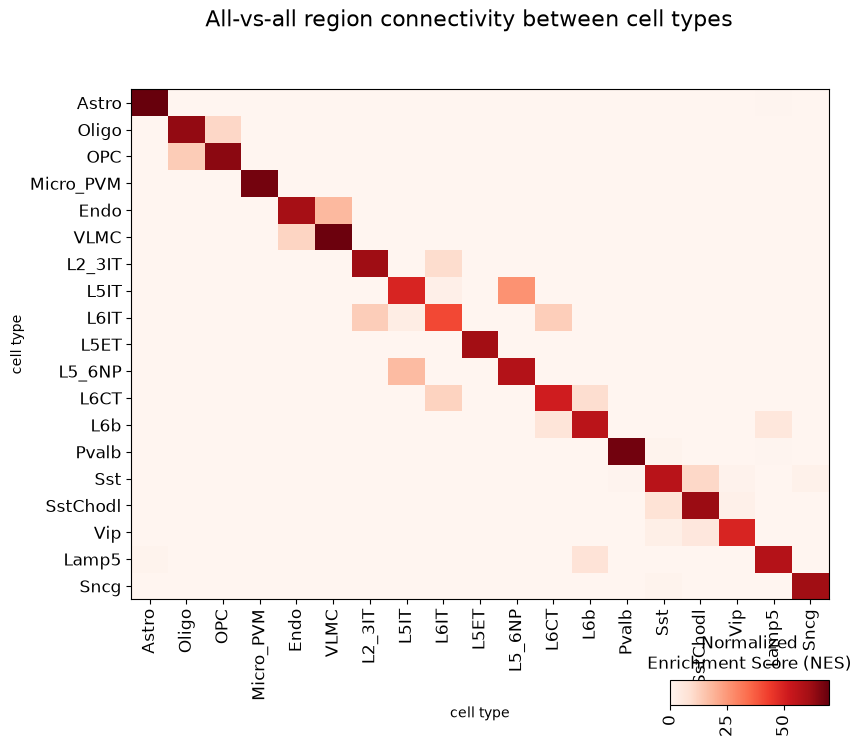

In [30]:
tm.pl.cell_type_nes_heatmap(region_adata, row_order=CELL_TYPES, col_order=CELL_TYPES,
                            x_label_rotation=90, width=9, height=8)

The diagonal is dark everywhere, which is the sanity check: enhancers of a cell type are reliably neighbours of other enhancers of the same cell type. The interesting information is also off the diagonal, and there is less of it than the t-SNE suggested.

**Clear pairs.** `Oligo`–`OPC` and `Endo`–`VLMC` light up strongly, as they did in the embedding. So do `Sst`–`SstChodl`, `L6CT`–`L6b`, and `L5IT`–`L5_6NP`. Every one of these is a pair of cell types that are developmentally or functionally close, and the test says their enhancers are built from overlapping code.

**Cell types that are alone.** `Micro_PVM` has nothing off its diagonal, which we expected. But neither does **`Astro`** — and that is a genuine correction to the previous plot. In the t-SNE the astrocytes sat inside the big neuronal mass, and it was tempting to read that as "astrocyte enhancers resemble neuronal ones". The enrichment test says they do not: astrocyte enhancers are no more likely to neighbour a neuronal enhancer than chance allows. They were *placed* among the neurons because a two-dimensional layout has to put them somewhere, not because they belong there.

That is exactly why this step exists. A t-SNE preserves local neighbourhoods and distorts everything else, so distances between groups on the page are not distances in the data. When a question is about *how close* two groups are, measure it; do not read it off the picture.

**Question**: `Pvalb` sits in the middle of the inhibitory block in the t-SNE, yet shows no off-diagonal enrichment here. Give two different explanations, and say which you could test with the data in this notebook.

### Step 13: How far can motif content alone reproduce the cell types?

The previous plot is suggestive, but "they separate reasonably well" is not a number. Here we make it one.

`tm.tl.optimal_hierarchical_clustering` builds a tree over the enhancer embedding, cuts it at a hundred different heights, and keeps the cut whose groups agree best with the cell-type labels. Be clear about what that means: **it uses the cell types as the answer key**, so this is not an unsupervised discovery. It measures something more specific and more useful — the best that a partition based purely on motif content can do against the partition we actually care about. The agreement is reported as the **adjusted Rand index** (ARI), which is 0 for a random partition and 1 for a perfect match.

Afterwards, `tm.tl.get_region_profiles` describes each group by the motif families its enhancers contain, so we can ask what the groups are made of.

 [clustering] Seeding embedding space with leiden clusters...


 [clustering] Build hierarchical tree...

 [clustering] Cutting at height 0.0


 [clustering] Cutting at height 0.01


 [clustering] Cutting at height 0.02


 [clustering] Cutting at height 0.03


 [clustering] Cutting at height 0.04

... (92 outputs left out)


 [clustering] Cutting at height 0.97


 [clustering] Cutting at height 0.98


 [clustering] Cutting at height 0.99


 [clustering] The optimal resolution is 0.28 with an ARI of 0.4109094110790966
 [clustering] Saved clusters in .obs region_cluster
 [clustering] Plotting...


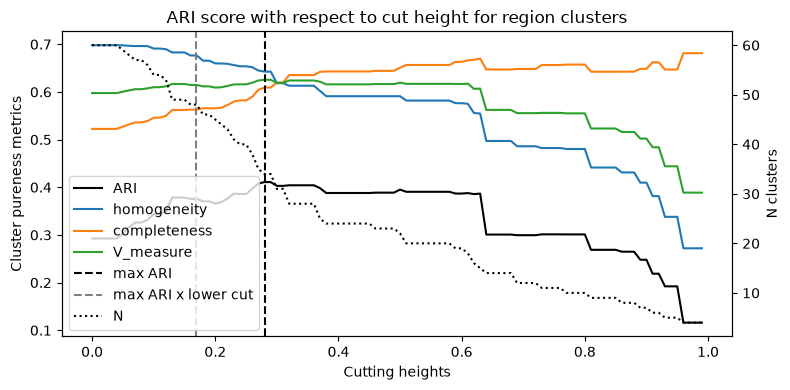

region_cluster
H14    461
H0     434
H5     368
H43    309
H35    291
H10    276
H30    210
H39    203
H12    163
H19    161
H6     149
H4     149
H44    145
H24    143
H17    142
H40    139
H13    131
H46    124
H37    108
H34    104
H31    103
H8     101
H16     98
H47     98
H11     90
H25     85
H7      71
H28     63
H27     62
H9      57
H18     56
H42     54
H32     51
H22     51
H15     50
H26     50
H1      50
H29     48
H3      37
H21     33
H45     32
H23     32
H20     30
H2      30
H33     28
H36     11
H41     10
H38      9


In [31]:
tm.tl.optimal_hierarchical_clustering(region_adata, lower_cut=0.6)
print(region_adata.obs["region_cluster"].value_counts().to_string())

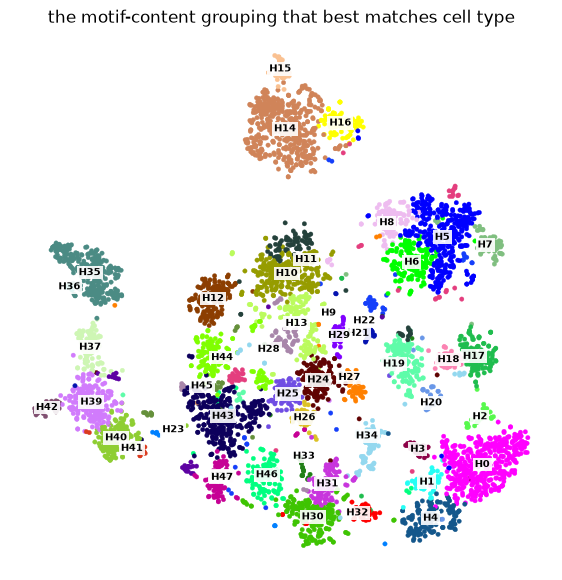

In [32]:
_ = tm.pl.region_tsne(region_adata, color_by="region_cluster", plot_legend=False, plot_labels=True,
                      fig_edge=7, dot_size=10,
                      title="the motif-content grouping that best matches cell type")

motif content of the largest group:


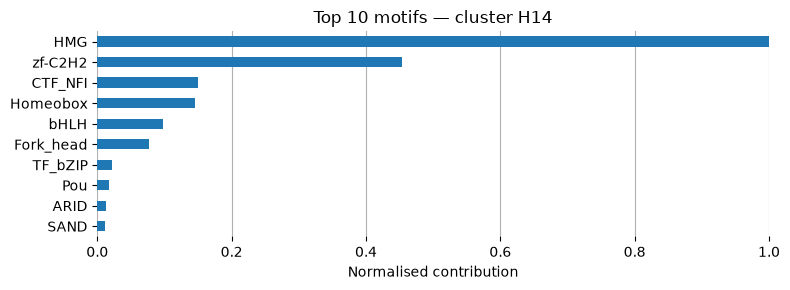

In [33]:
profiles = tm.tl.get_region_profiles(adata, region_adata,
                                     annotation_col="tf_family",
                                     region_cluster_col="region_cluster")
largest = region_adata.obs["region_cluster"].value_counts().idxmax()
print("motif content of the largest group:")
tm.pl.plot_top_motifs(profiles, region_cluster=largest)

Two numbers come out of this, and both are more interesting than a clean success would have been.

**The best agreement is an ARI of about 0.4.** Not 0.9. Describing an enhancer by the motifs it contains captures a real part of what makes it belong to a cell type — 0.4 is far above chance — but it is nowhere near the whole story. The model that produced these contribution scores separates the 19 cell types confidently; our motif description does not. What we threw away is the usual list: how many copies of each motif, how good each match is, how the sites are spaced and ordered, and everything the flanking sequence contributes.

**The best agreement needs 48 groups for 19 cell types.** Even at its most favourable cut, motif content does not carve the data into 19 pieces. It carves it into roughly two and a half times as many. The enhancers of one cell type come in several distinct motif flavours — which is what you would expect if a cell type uses more than one regulatory programme, for instance enhancers driven by different TF combinations in different contexts.

The bar chart shows what the largest group is built from: `bHLH`, then `zf-C2H2` and `Homeobox`. Compare it with the code table of Step 8 and you can see which cell types that combination belongs to.

**Question**: If you increased the number of regions per cell type from 300 to 2,000, would you expect the ARI to go up, down, or stay the same? Give a reason for your answer.

### Step 14: Save the results

We save the seqlet object, the consensus patterns and the cluster table. Part 2 uses the predictions and the patterns to design synthetic enhancers.

In [34]:
# one row per motif cluster: who uses it, how exclusively, and what it reads
cluster_table = pd.crosstab(adata.obs["leiden"], adata.obs["cell_type"])
shares = cluster_table.div(cluster_table.sum(axis=1), axis=0)
cluster_table["cell type"] = shares.idxmax(axis=1)
cluster_table["share"] = shares.max(axis=1).round(2)
cluster_table["TF family"] = cluster_family
cluster_table["motif"] = [consensus(patterns.get(c))[0] for c in cluster_table.index]
cluster_table["information"] = [round(consensus(patterns.get(c))[1], 2) for c in cluster_table.index]

tm.save_h5ad(adata, RESULTS / "seqlets_biccn.h5ad")
tm.save_patterns(patterns, RESULTS / "patterns_biccn.pkl")
cluster_table.to_csv(RESULTS / "seqlet_clusters_per_cell_type.csv")
print("saved to", RESULTS)

saved to results


## Conclusion

1. **Contribution scores become a vocabulary.** TF-MINDI cut 51,000 seqlets out of 5,700 enhancers, matched each to a motif collection and clustered them, exactly the way you clustered nuclei in the single-nucleus RNA-seq practical. Out came the known master regulators of cortical cell types — `IRF` and `ETS` for microglia, `HMG`/SOX for the oligodendrocyte lineage, `Fork_head` for the vascular cells, `CTF_NFI` for astrocytes, `Homeobox` for the inhibitory interneurons — without us naming a single transcription factor in advance.
2. **The code has two axes, not one.** The code table separates *how often* a motif is used from *how much the model leans on it*. They come apart: `zf-C2H2` motifs appear in nearly every enhancer of every cell type but contribute weakly, while the `IRF` motif appears rarely and only in microglia, where it is the single strongest signal in the whole table. "Common" and "important" are different questions.
3. **Expression narrows the candidates, and shows where sequence stops.** Correlating motif use against the RNA of the same nuclei named `Sox10` for the oligodendrocyte lineage and `Tbr1` for excitatory neurons. But one `Fork_head` cluster matched twelve different FOX factors, and the microglial `ETS` cluster matched eight. Sequence identifies the family, expression identifies which members are present, and neither identifies the protein on the DNA.
4. **Motifs are a large part of the code, not all of it.** Describing an enhancer purely by its motif content reproduces the cell-type partition with an ARI of about 0.4, using roughly 45 groups for 19 cell types. The embedding separates **lineages** cleanly — oligodendrocytes with their precursors, endothelium with VLMC, microglia alone — and grades within them. What is missing is copy number, match quality and the arrangement of sites, all of which the model uses and our description throws away.

In [part 2](part_2_enhancer_design.ipynb) we put this code to the test: we use the motifs we just discovered to design new enhancers that do not exist in any genome, and check whether they push a sequence towards the cell type we choose.

## Exercises

1. **More or fewer regions.** Change `N_PER_CELL_TYPE` from 300 to 100 or 600. Which clusters survive, and which conclusions are robust?
2. **Seqlet threshold.** Change the `threshold` in `extract_seqlets` from 0.01 to 0.05. How many seqlets do you get, and what happens to the low-information clusters?
3. **Another seqlet caller.** Run `extract_seqlets` with `method="recursive_raw"`, which only finds stretches that push the prediction *up*. How many seqlets do you lose, and which kind of binding site can you no longer detect?
4. **Fewer cell types.** Restrict `CELL_TYPES` to the six non-neuronal ones and rerun. Which motif clusters disappear, and what happens to the TF-expression correlations when they rest on six points instead of 19?
5. **Another known locus.** Repeat Step 3 for the *Dlx1*/*Dlx2* intergenic region, which carries its own forebrain enhancers. Do its peaks look inhibitory too?
6. **Your own enhancer.** Take the most specific region of a cell type from Step 5, compute its contribution scores, and compare the motifs you see with the clusters of that cell type in Step 8.

### References and further reading

1. Kempynck N, De Winter S, et al. (2026). CREsted: modeling genomic and synthetic cell-type-specific enhancers across tissues and species. *Nature Methods*. [Link](https://doi.org/10.1038/s41592-026-03057-2)
2. Zemke NR, Armand EJ, Wang W, et al. (2023). Conserved and divergent gene regulatory programs of the mammalian neocortex. *Nature* 624, 390–402. [Link](https://doi.org/10.1038/s41586-023-06819-6)
3. [CREsted documentation](https://crested.readthedocs.io/en/stable/) and the [DeepBICCN2 model page](https://crested.readthedocs.io/en/stable/models/BICCN/deepbiccn2.html).
4. [TF-MINDI documentation](https://tf-mindi.readthedocs.io/en/latest/).
5. Zerucha T, Stühmer T, Hatch G, et al. (2000). A highly conserved enhancer in the Dlx5/Dlx6 intergenic region is the site of cross-regulatory interactions between Dlx genes in the embryonic forebrain. *Journal of Neuroscience* 20(2), 709–721. [Link](https://doi.org/10.1523/JNEUROSCI.20-02-00709.2000) — the enhancers mI56i and mI56ii used in Step 3.
6. Dimidschstein J, Chen Q, Tremblay R, et al. (2016). A viral strategy for targeting and manipulating interneurons across vertebrate species. *Nature Neuroscience* 19(12), 1743–1749. [Link](https://doi.org/10.1038/nn.4430) — mI56i as the mDlx enhancer for GABAergic interneurons.
7. Sundararajan M, Taly A, Yan Q (2017). Axiomatic attribution for deep networks (integrated gradients). *ICML*.
8. Gupta S, et al. (2007). Quantifying similarity between motifs (TomTom). *Genome Biology* 8, R24.